In [15]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler

from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, confusion_matrix,
                             precision_recall_curve, balanced_accuracy_score)

import keras
from keras.models import Sequential
from keras.layers import Input, Dense, Dropout
from keras.callbacks import EarlyStopping, ModelCheckpoint

from preprocessing import prepare_data

In [ ]:
batch_size = 20
lr = 0.003
strat="season_median"
split_t="recent20"

scaler_name = "minmax"
SCALERS = {"minmax": MinMaxScaler, "standard": StandardScaler, "none": None}

class_wei = None

# Prepare data

In [17]:
X_train_val, y_train_val, X_test, y_test = prepare_data(strat, 
                                                        split_t, 
                                                        one_hot_cluster=True, 
                                                        sin_doy=True)

In [18]:
# Split train and validation: _train_val -> _train , _val
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.15, random_state=42, stratify=y_train_val)

In [19]:
# Scaling: fit on train only, continuous columns only

# Continuous columns only (> 2 distinct values)
num_names = [c for c in X_train.columns if X_train[c].nunique() > 2]

X_train, X_val, X_test = X_train.copy(), X_val.copy(), X_test.copy()

# Scaling: fit on train only
if SCALERS[scaler_name] is not None:
    scaler = SCALERS[scaler_name]().fit(X_train[num_names])
    for A in (X_train, X_val, X_test):
        A[num_names] = scaler.transform(A[num_names])

In [20]:
display(X_train.describe())
display(X_val.describe())
display(X_test.describe())

,SST,UI,YDOY,sin_doy,CHL_log,CHL_uncertainty,cluster_0,cluster_1,cluster_2,cluster_4,cluster_5
count,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000,767.00000,767.000000,767.000000,767.000000,767.000000
mean,0.363639,0.460830,0.484499,0.492246,0.401844,0.354752,0.46545,0.009126,0.054759,0.279009,0.191656
std,0.177875,0.103142,0.344415,0.362529,0.129164,0.194708,0.49913,0.095158,0.227657,0.448805,0.393861
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000
25%,0.232949,0.434908,0.158036,0.129386,0.338221,0.268068,0.00000,0.000000,0.000000,0.000000,0.000000
50%,0.346275,0.459636,0.450613,0.457017,0.406803,0.287946,0.00000,0.000000,0.000000,0.000000,0.000000
75%,0.466946,0.496638,0.819432,0.869163,0.424547,0.419091,1.00000,0.000000,0.000000,1.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000


,SST,UI,YDOY,sin_doy,CHL_log,CHL_uncertainty,cluster_0,cluster_1,cluster_2,cluster_4,cluster_5
count,136.000000,136.000000,136.000000,136.000000,136.000000,136.000000,136.000000,136.000000,136.000000,136.000000,136.000000
mean,0.357632,0.459621,0.514100,0.530260,0.428722,0.364359,0.448529,0.014706,0.058824,0.294118,0.183824
std,0.176076,0.110878,0.360849,0.347195,0.138623,0.203457,0.499182,0.120818,0.236164,0.457330,0.388772
min,0.018888,-0.089504,0.000000,0.001333,0.111475,0.039502,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.237408,0.428874,0.177324,0.217551,0.338221,0.268068,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.332109,0.460576,0.523683,0.545126,0.406803,0.285215,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.453305,0.496088,0.876386,0.879854,0.424547,0.419091,1.000000,0.000000,0.000000,1.000000,0.000000
max,0.857293,0.970148,1.000000,0.999963,0.972223,1.092341,1.000000,1.000000,1.000000,1.000000,1.000000


,SST,UI,YDOY,sin_doy,CHL_log,CHL_uncertainty,cluster_0,cluster_1,cluster_2,cluster_4,cluster_5
count,160.000000,160.000000,160.000000,160.000000,160.000000,160.000000,160.00000,160.000000,160.000000,160.000000,160.000000
mean,0.348872,0.509260,0.444833,0.497143,0.419688,0.413281,0.41250,0.012500,0.106250,0.312500,0.156250
std,0.169320,0.086695,0.340356,0.364254,0.182938,0.274440,0.49383,0.111451,0.309125,0.464968,0.364232
min,0.043022,0.235165,0.000148,0.000000,-0.023595,0.051061,0.00000,0.000000,0.000000,0.000000,0.000000
25%,0.224554,0.463359,0.119483,0.125799,0.301074,0.164042,0.00000,0.000000,0.000000,0.000000,0.000000
50%,0.312697,0.488331,0.395396,0.487091,0.400500,0.338689,0.00000,0.000000,0.000000,0.000000,0.000000
75%,0.446485,0.534134,0.761693,0.868438,0.544635,0.656770,1.00000,0.000000,0.000000,1.000000,0.000000
max,0.983211,0.853354,1.000000,1.000000,0.955337,0.942589,1.00000,1.000000,1.000000,1.000000,1.000000


In [21]:
pd.concat({"train": X_train.describe().T,
           "val":   X_val.describe().T,
           "test":  X_test.describe().T}, axis=1)[["train", "val", "test"]].round(3)

train                                                 val  \
                 count   mean    std  min    25%    50%    75%  max  count   
SST              767.0  0.364  0.178  0.0  0.233  0.346  0.467  1.0  136.0   
UI               767.0  0.461  0.103  0.0  0.435  0.460  0.497  1.0  136.0   
YDOY             767.0  0.484  0.344  0.0  0.158  0.451  0.819  1.0  136.0   
sin_doy          767.0  0.492  0.363  0.0  0.129  0.457  0.869  1.0  136.0   
CHL_log          767.0  0.402  0.129  0.0  0.338  0.407  0.425  1.0  136.0   
CHL_uncertainty  767.0  0.355  0.195  0.0  0.268  0.288  0.419  1.0  136.0   
cluster_0        767.0  0.465  0.499  0.0  0.000  0.000  1.000  1.0  136.0   
cluster_1        767.0  0.009  0.095  0.0  0.000  0.000  0.000  1.0  136.0   
cluster_2        767.0  0.055  0.228  0.0  0.000  0.000  0.000  1.0  136.0   
cluster_4        767.0  0.279  0.449  0.0  0.000  0.000  1.000  1.0  136.0   
cluster_5        767.0  0.192  0.394  0.0  0.000  0.000  0.000  1.0  136.0   

                        ...                 test                              \
                  mean  ...    75%    max  count   mean    std    min    25%   
SST              0.358  ...  0.453  0.857  160.0  0.349  0.169  0.043  0.225   
UI               0.460  ...  0.496  0.970  160.0  0.509  0.087  0.235  0.463   
YDOY             0.514  ...  0.876  1.000  160.0  0.445  0.340  0.000  0.119   
sin_doy          0.530  ...  0.880  1.000  160.0  0.497  0.364  0.000  0.126   
CHL_log          0.429  ...  0.425  0.972  160.0  0.420  0.183 -0.024  0.301   
CHL_uncertainty  0.364  ...  0.419  1.092  160.0  0.413  0.274  0.051  0.164   
cluster_0        0.449  ...  1.000  1.000  160.0  0.412  0.494  0.000  0.000   
cluster_1        0.015  ...  0.000  1.000  160.0  0.012  0.111  0.000  0.000   
cluster_2        0.059  ...  0.000  1.000  160.0  0.106  0.309  0.000  0.000   
cluster_4        0.294  ...  1.000  1.000  160.0  0.312  0.465  0.000  0.000   
cluster_5        0.184  ...  0.000  1.000  160.0  0.156  0.364  0.000  0.000   

                                      
                   50%    75%    max  
SST              0.313  0.446  0.983  
UI               0.488  0.534  0.853  
YDOY             0.395  0.762  1.000  
sin_doy          0.487  0.868  1.000  
CHL_log          0.401  0.545  0.955  
CHL_uncertainty  0.339  0.657  0.943  
cluster_0        0.000  1.000  1.000  
cluster_1        0.000  0.000  1.000  
cluster_2        0.000  0.000  1.000  
cluster_4        0.000  1.000  1.000  
cluster_5        0.000  0.000  1.000  

[11 rows x 24 columns]

In [22]:
# Convert for Keras
feature_names = X_train.columns.tolist()
X_train, X_val, X_test = (A.to_numpy(dtype="float32") for A in (X_train, X_val, X_test))


# MLP's

In [23]:
THRESHOLD = None

# A
dropA=0.0
RegulA=True
RegA=0

epochA=50
patA=10


#B
dropB=0.4
RegulB=True
RegB=1e-4

epochB=50
patB=40

## NN

### Functions

In [24]:
def build_mlp(units, dropout=0.0, name="mlp", Regul=True, Reg=1e-4, seed=42):
    keras.utils.set_random_seed(seed)          # same initial weights every time
    m = Sequential(name=name)
    m.add(Input(shape=(X_test.shape[1],)))
    for u in units:
        if Regul:
            m.add(Dense(u, activation="relu", kernel_regularizer=keras.regularizers.l2(Reg)))
        else:
            m.add(Dense(u, activation="relu"))
        if dropout > 0:
            m.add(Dropout(dropout))
    m.add(Dense(1, activation="sigmoid"))          # binary output
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
              loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return m


def train(model, name, n_epochs, pat):
    cbs = [EarlyStopping(monitor="val_auc", mode="max", patience=pat,
              start_from_epoch=20, restore_best_weights=True),
           ModelCheckpoint(f"best_{name}.keras", monitor="val_auc", mode="max", save_best_only=True)]
    return model.fit(X_train, y_train, epochs=n_epochs, batch_size=batch_size,
                     validation_data=(X_val, y_val), callbacks=cbs,
                     class_weight=class_wei, verbose=1)

### Neural Network 1

In [25]:
# Model A: small (like the example notebook)
model_A = build_mlp([16, 8], 
                    dropout=dropA, 
                    name="NN_A", 
                    Regul=RegulA, 
                    Reg=RegA)

model_A.summary()

hist_A = train(model_A, "NN_A", epochA, pat=patA)

Model: "NN_A"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 16)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 337 (1.32 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8774 - auc: 0.5406 - loss: 0.4081 - val_accuracy: 0.8750 - val_auc: 0.7973 - val_loss: 0.3421
Epoch 2/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8774 - auc: 0.7333 - loss: 0.3439 - val_accuracy: 0.8750 - val_auc: 0.7981 - val_loss: 0.3267
Epoch 3/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8774 - auc: 0.7552 - loss: 0.3324 - val_accuracy: 0.8750 - val_auc: 0.8094 - val_loss: 0.3157
Epoch 4/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8774 - auc: 0.7647 - loss: 0.3256 - val_accuracy: 0.8750 - val_auc: 0.8171 - val_loss: 0.3079
Epoch 5/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8774 - auc: 0.7751 - loss: 0.3205 - val_accuracy: 0.8750 - val_auc: 0.8233 - val_loss: 0.3007
Epoch 6/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8774 - auc: 0.7842 - loss: 0.3163 - val_accuracy: 0.8750 - val_auc: 0.8309 - val_loss: 0.2959
Epoch 7/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step -

### Neural Network 2

In [26]:
model_B = build_mlp([64, 32], 
                    dropout=dropB, 
                    name="NN_B", 
                    Regul=RegulB, 
                    Reg=RegB)

model_B.summary()

hist_B = train(model_B, "NN_B", epochB, pat=patB)

Model: "NN_B"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,881 (11.25 KB)

 Trainable params: 2,881 (11.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.8435 - auc: 0.5077 - loss: 0.4595 - val_accuracy: 0.8750 - val_auc: 0.7375 - val_loss: 0.3585
Epoch 2/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8774 - auc: 0.6623 - loss: 0.3622 - val_accuracy: 0.8750 - val_auc: 0.8282 - val_loss: 0.3165
Epoch 3/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8774 - auc: 0.7382 - loss: 0.3372 - val_accuracy: 0.8750 - val_auc: 0.8376 - val_loss: 0.2998
Epoch 4/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8774 - auc: 0.7919 - loss: 0.3158 - val_accuracy: 0.8750 - val_auc: 0.8458 - val_loss: 0.2914
Epoch 5/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8774 - auc: 0.7640 - loss: 0.3274 - val_accuracy: 0.8750 - val_auc: 0.8423 - val_loss: 0.2929
Epoch 6/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8774 - auc: 0.7921 - loss: 0.3138 - val_accuracy: 0.8750 - val_auc: 0.8463 - val_loss: 0.2887
Epoch 7/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step -

## Plots and Metrics

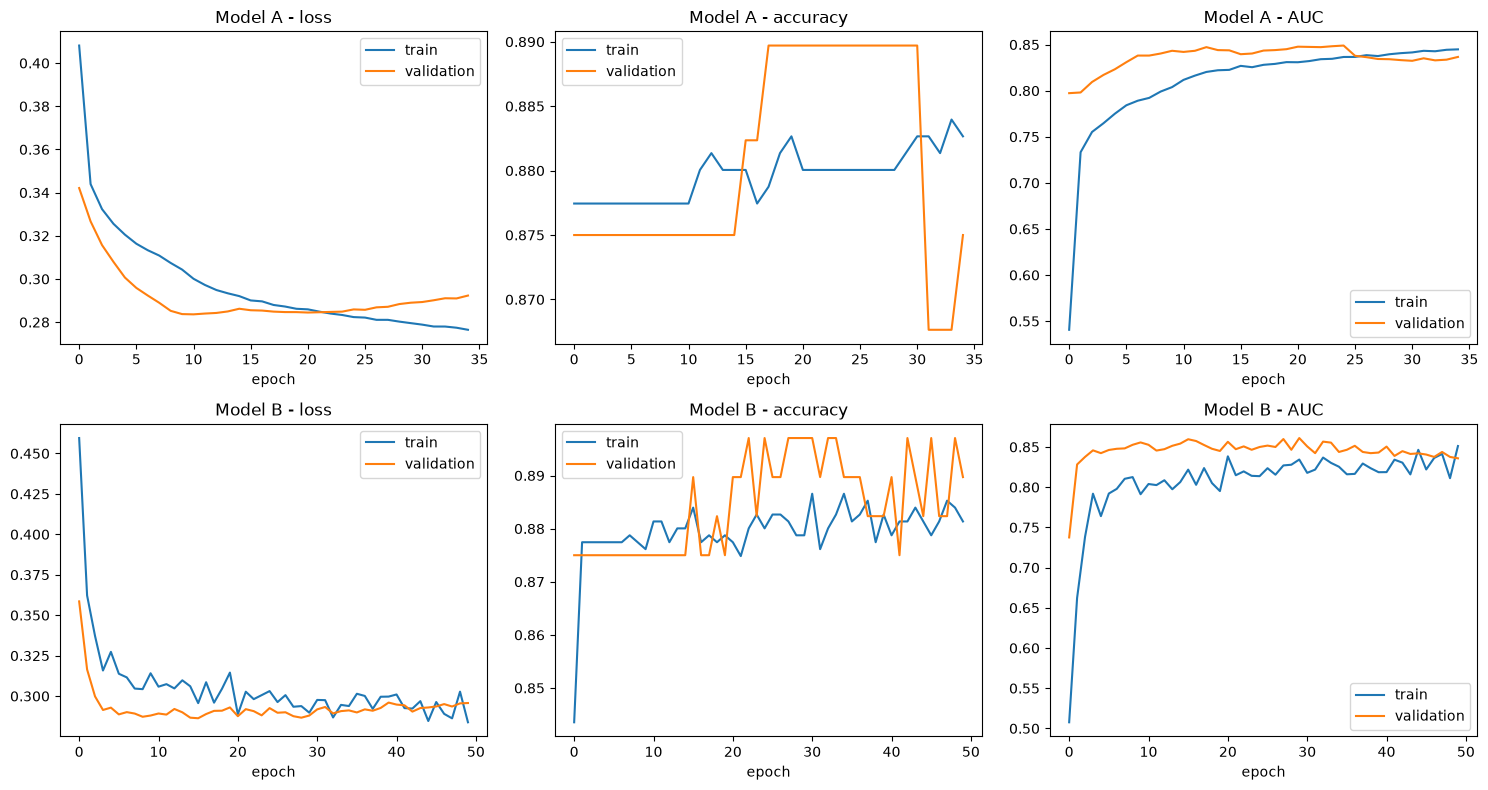

In [27]:
# Training curves: loss, accuracy and AUC (train vs validation)
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for row, (h, title) in enumerate([(hist_A, "Model A"), (hist_B, "Model B")]):
    for col, (metric, label) in enumerate([("loss", "loss"), ("accuracy", "accuracy"), ("auc", "AUC")]):
        ax[row, col].plot(h.history[metric], label="train")
        ax[row, col].plot(h.history["val_" + metric], label="validation")
        ax[row, col].set_title(f"{title} - {label}")
        ax[row, col].set_xlabel("epoch")
        ax[row, col].legend()
plt.tight_layout(); plt.show()

In [28]:
def report(model, name):
    ytr, yva, yte = y_train.astype(int), y_val.astype(int), y_test.astype(int)
    p_tr = model.predict(X_train, verbose=0).ravel()
    p_va = model.predict(X_val,   verbose=0).ravel()
    p_te = model.predict(X_test,  verbose=0).ravel()

    if THRESHOLD is None:
        prec, rec, thr = precision_recall_curve(yva, p_va)
        f1 = 2 * prec * rec / (prec + rec + 1e-12)
        t = float(thr[np.argmax(f1[:-1])])
    else:
        t = THRESHOLD

    pred = lambda p: (p >= t).astype(int)

    print(f"===== {name} =====")
    for label, y, p in [("Train      ", ytr, p_tr), ("Validation ", yva, p_va), ("Test       ", yte, p_te)]:
        print(f"{label} accuracy = {accuracy_score(y, pred(p)):.4f} | "
              f"balanced acc = {balanced_accuracy_score(y, pred(p)):.4f} | "
              f"AUC = {roc_auc_score(y, p):.4f}")

    print(f"\nThreshold used: {t:.3f}")

    yp = pred(p_te)
    print(f"\n* accuracy on test         : {accuracy_score(yte, yp):.4f}")
    print(f"* balanced accuracy on test: {balanced_accuracy_score(yte, yp):.4f}")
    print(f"* precision on test        : {precision_score(yte, yp, zero_division=0):.4f}")
    print(f"* recall on test           : {recall_score(yte, yp, zero_division=0):.4f}")
    print(f"* f1-score on test         : {f1_score(yte, yp, zero_division=0):.4f}")

    print("\nConfusion matrix (rows = true 0/1, cols = predicted 0/1):")
    print(confusion_matrix(yte, yp))
    print()

report(model_A, "NN_A")
report(model_B, "NN_B")

===== NN_A =====
Train       accuracy = 0.8305 | balanced acc = 0.7341 | AUC = 0.8454
Validation  accuracy = 0.8456 | balanced acc = 0.8109 | AUC = 0.8453
Test        accuracy = 0.7875 | balanced acc = 0.7393 | AUC = 0.8198

Threshold used: 0.228

* accuracy on test         : 0.7875
* balanced accuracy on test: 0.7393
* precision on test        : 0.4186
* recall on test           : 0.6667
* f1-score on test         : 0.5143

Confusion matrix (rows = true 0/1, cols = predicted 0/1):
[[108  25]
 [  9  18]]

===== NN_B =====
Train       accuracy = 0.8774 | balanced acc = 0.5778 | AUC = 0.8460
Validation  accuracy = 0.9118 | balanced acc = 0.7227 | AUC = 0.8591
Test        accuracy = 0.8187 | balanced acc = 0.6106 | AUC = 0.8090

Threshold used: 0.408

* accuracy on test         : 0.8187
* balanced accuracy on test: 0.6106
* precision on test        : 0.4444
* recall on test           : 0.2963
* f1-score on test         : 0.3556

Confusion matrix (rows = true 0/1, cols = predicted 0/1):
[[